# A-share empirical validation

Actual historical prices on a retrospectively specified fixed basket. The default reversal input has not passed independent alpha discovery. This notebook consumes the entire declared evaluation, with no selection of favorable subperiods.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from risk_aware_portfolio.utils.paths import resolve_path
from risk_aware_portfolio.utils.config import load_config
from risk_aware_portfolio.utils.manifest import verify_manifest
from risk_aware_portfolio.reporting.real_validation import verify_real_data
config = load_config('configs/ashare.yaml')
output = resolve_path(config['real_data']['output_dir'])
verify_real_data(config)
verify_manifest(output / 'manifest.json', config, resolve_path(config['data']['input_path']))
display(pd.read_csv(output / 'tables/performance_summary.csv'))
display(pd.read_csv(output / 'tables/pairwise_comparisons.csv'))

,portfolio,annualized_return,annualized_volatility,sharpe,max_drawdown,calmar,average_turnover,average_rebalance_turnover,total_transaction_cost,annualized_active_return,...,effective_number_of_bets,normalized_effective_positions,gross_annualized_return,n_periods,sharpe_ci_lower,sharpe_ci_upper,mean,hac_standard_error,hac_t_stat,p_value
0,Baseline,-0.064963,0.164578,-0.326427,-0.204506,-0.317659,0.311400,1.500946,0.111213,-0.131889,...,11.996081,11.996081,0.050487,241.0,-2.474012,1.817709,-0.000523,0.000364,-1.436656,0.150816
1,Risk-Aware Portfolio,0.064212,0.123124,0.566722,-0.117155,0.548090,0.065165,0.314094,0.018870,-0.008389,...,35.616307,35.616307,0.085423,241.0,-1.435804,2.480521,-0.000033,0.000141,-0.236487,0.813055
2,Risk-Aware + TC,0.091272,0.123771,0.767314,-0.111196,0.820816,0.016513,0.079593,0.004180,0.016806,...,40.697755,40.697755,0.096052,241.0,-1.148142,2.677487,0.000067,0.000096,0.691195,0.489443
3,Neutralized Alpha Portfolio,0.116477,0.125465,0.940692,-0.106215,1.096618,0.017239,0.083091,0.004325,0.039858,...,39.304281,39.304281,0.121539,241.0,-0.937187,2.787545,0.000158,0.000085,1.859404,0.062970


,portfolio,comparison,mean,hac_standard_error,hac_t_stat,p_value,holm_p_value
0,Risk-Aware Portfolio,Baseline,0.000490,0.000326,1.501431,0.133244,0.236039
1,Risk-Aware + TC,Baseline,0.000590,0.000376,1.569654,0.116496,0.236039
2,Neutralized Alpha Portfolio,Baseline,0.000682,0.000388,1.758399,0.078680,0.236039


## Risk, attribution and temporal integrity

Forecast alpha is an accounting proxy, not identified true alpha. Effective-date data joins do not certify historical publication availability.

In [2]:
for name in ['risk_summary', 'attribution_summary', 'covariance_method_comparison', 'no_lookahead_checks', 'risk_aware_tc_solver_status']:
    display(pd.read_csv(output / f'tables/{name}.csv'))

,portfolio,average_predicted_volatility,realized_gross_volatility,mean_squared_return_to_variance,qlike,average_factor_risk_fraction,average_specific_risk_fraction,maximum_repair_variance_adjustment
0,Baseline,0.167444,0.163869,0.986522,-8.157420,0.881947,0.118053,6.776264e-20
1,Risk-Aware Portfolio,0.123636,0.123159,1.052272,-8.673631,0.946320,0.053680,8.639736e-20
2,Risk-Aware + TC,0.123467,0.123788,1.066363,-8.667490,0.952182,0.047818,9.740879e-20
3,Neutralized Alpha Portfolio,0.124014,0.125485,1.078790,-8.649078,0.952640,0.047360,8.385626e-20


,portfolio,factor,alpha_forecast,specific_after_alpha,transaction_cost,total
0,Baseline,0.026177,0.118996,-0.091383,-0.116008,-0.062217
1,Risk-Aware Portfolio,0.093727,0.033715,-0.045595,-0.020522,0.061324
2,Risk-Aware + TC,0.099527,0.005739,-0.013592,-0.004555,0.087119
3,Neutralized Alpha Portfolio,0.095822,0.006976,0.013097,-0.004774,0.111121


,method,n_forecasts,mean_effective_observations,mean_asset_condition_number,mean_factor_condition_number,minimum_asset_eigenvalue,maximum_asset_eigenvalue,minimum_factor_eigenvalue,mean_relative_covariance_change,mean_relative_factor_covariance_error
0,sample,294,119.142857,195.037736,115.070579,0.000026,0.008660,1.752520e-06,0.047148,NaN
1,ewma,294,32.240378,211.948217,170.218395,0.000019,0.014225,7.090498e-07,0.112310,NaN


,check,cutoff,passed,maximum_weight_difference
0,prefix_invariance,2023-02-21,True,0.0
1,future_perturbation,2023-02-21,True,0.0


,status,count
0,held,191
1,optimal,42
2,optimal_inaccurate,8


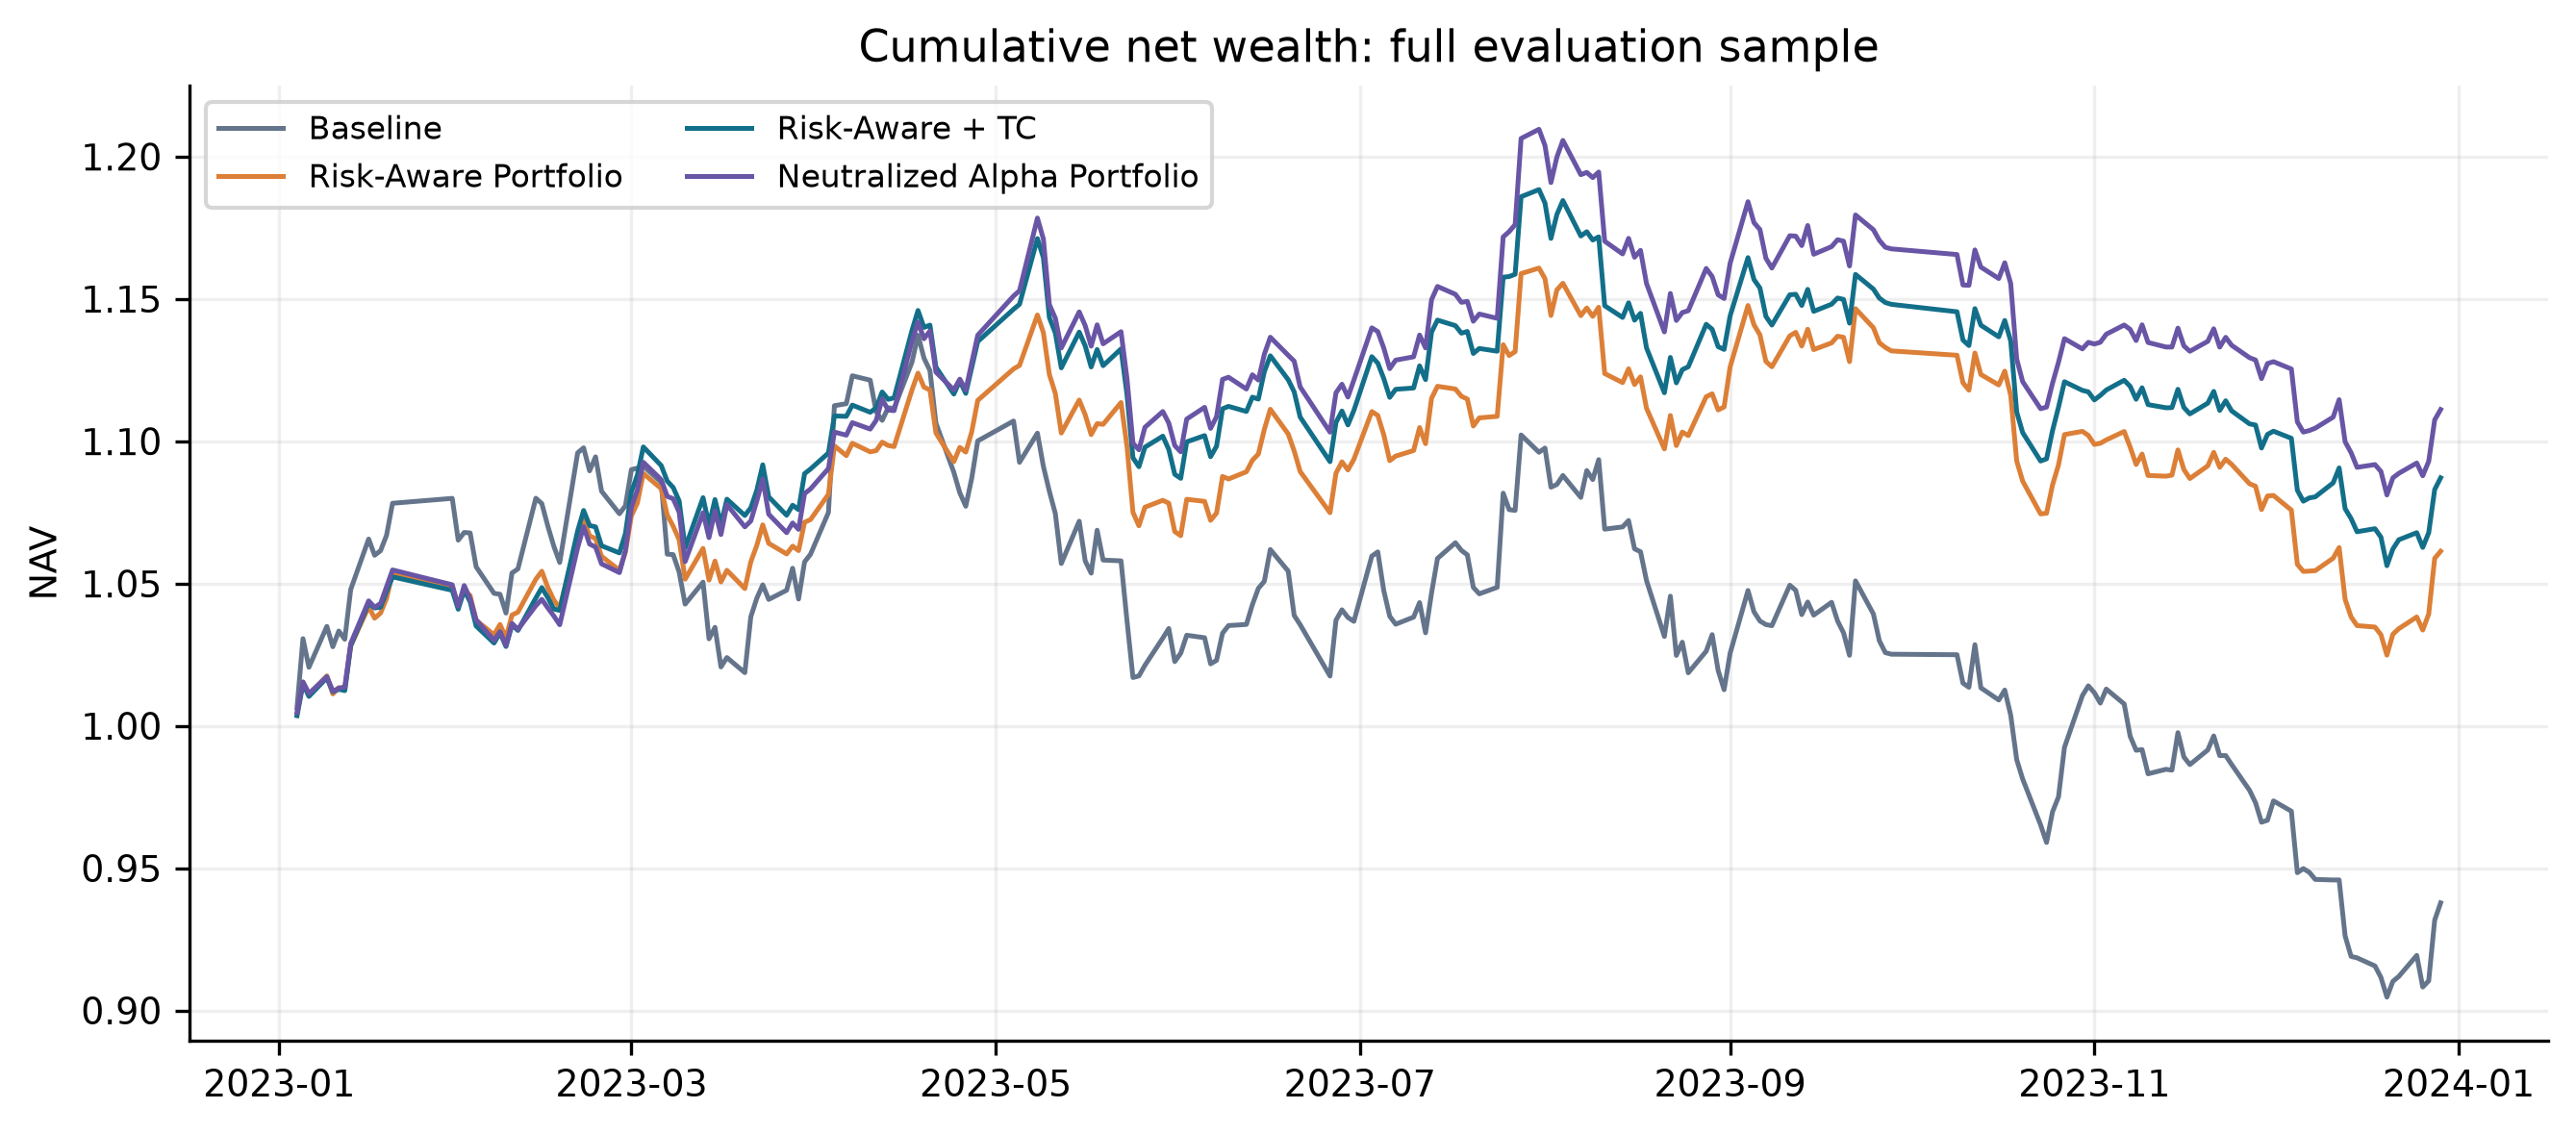

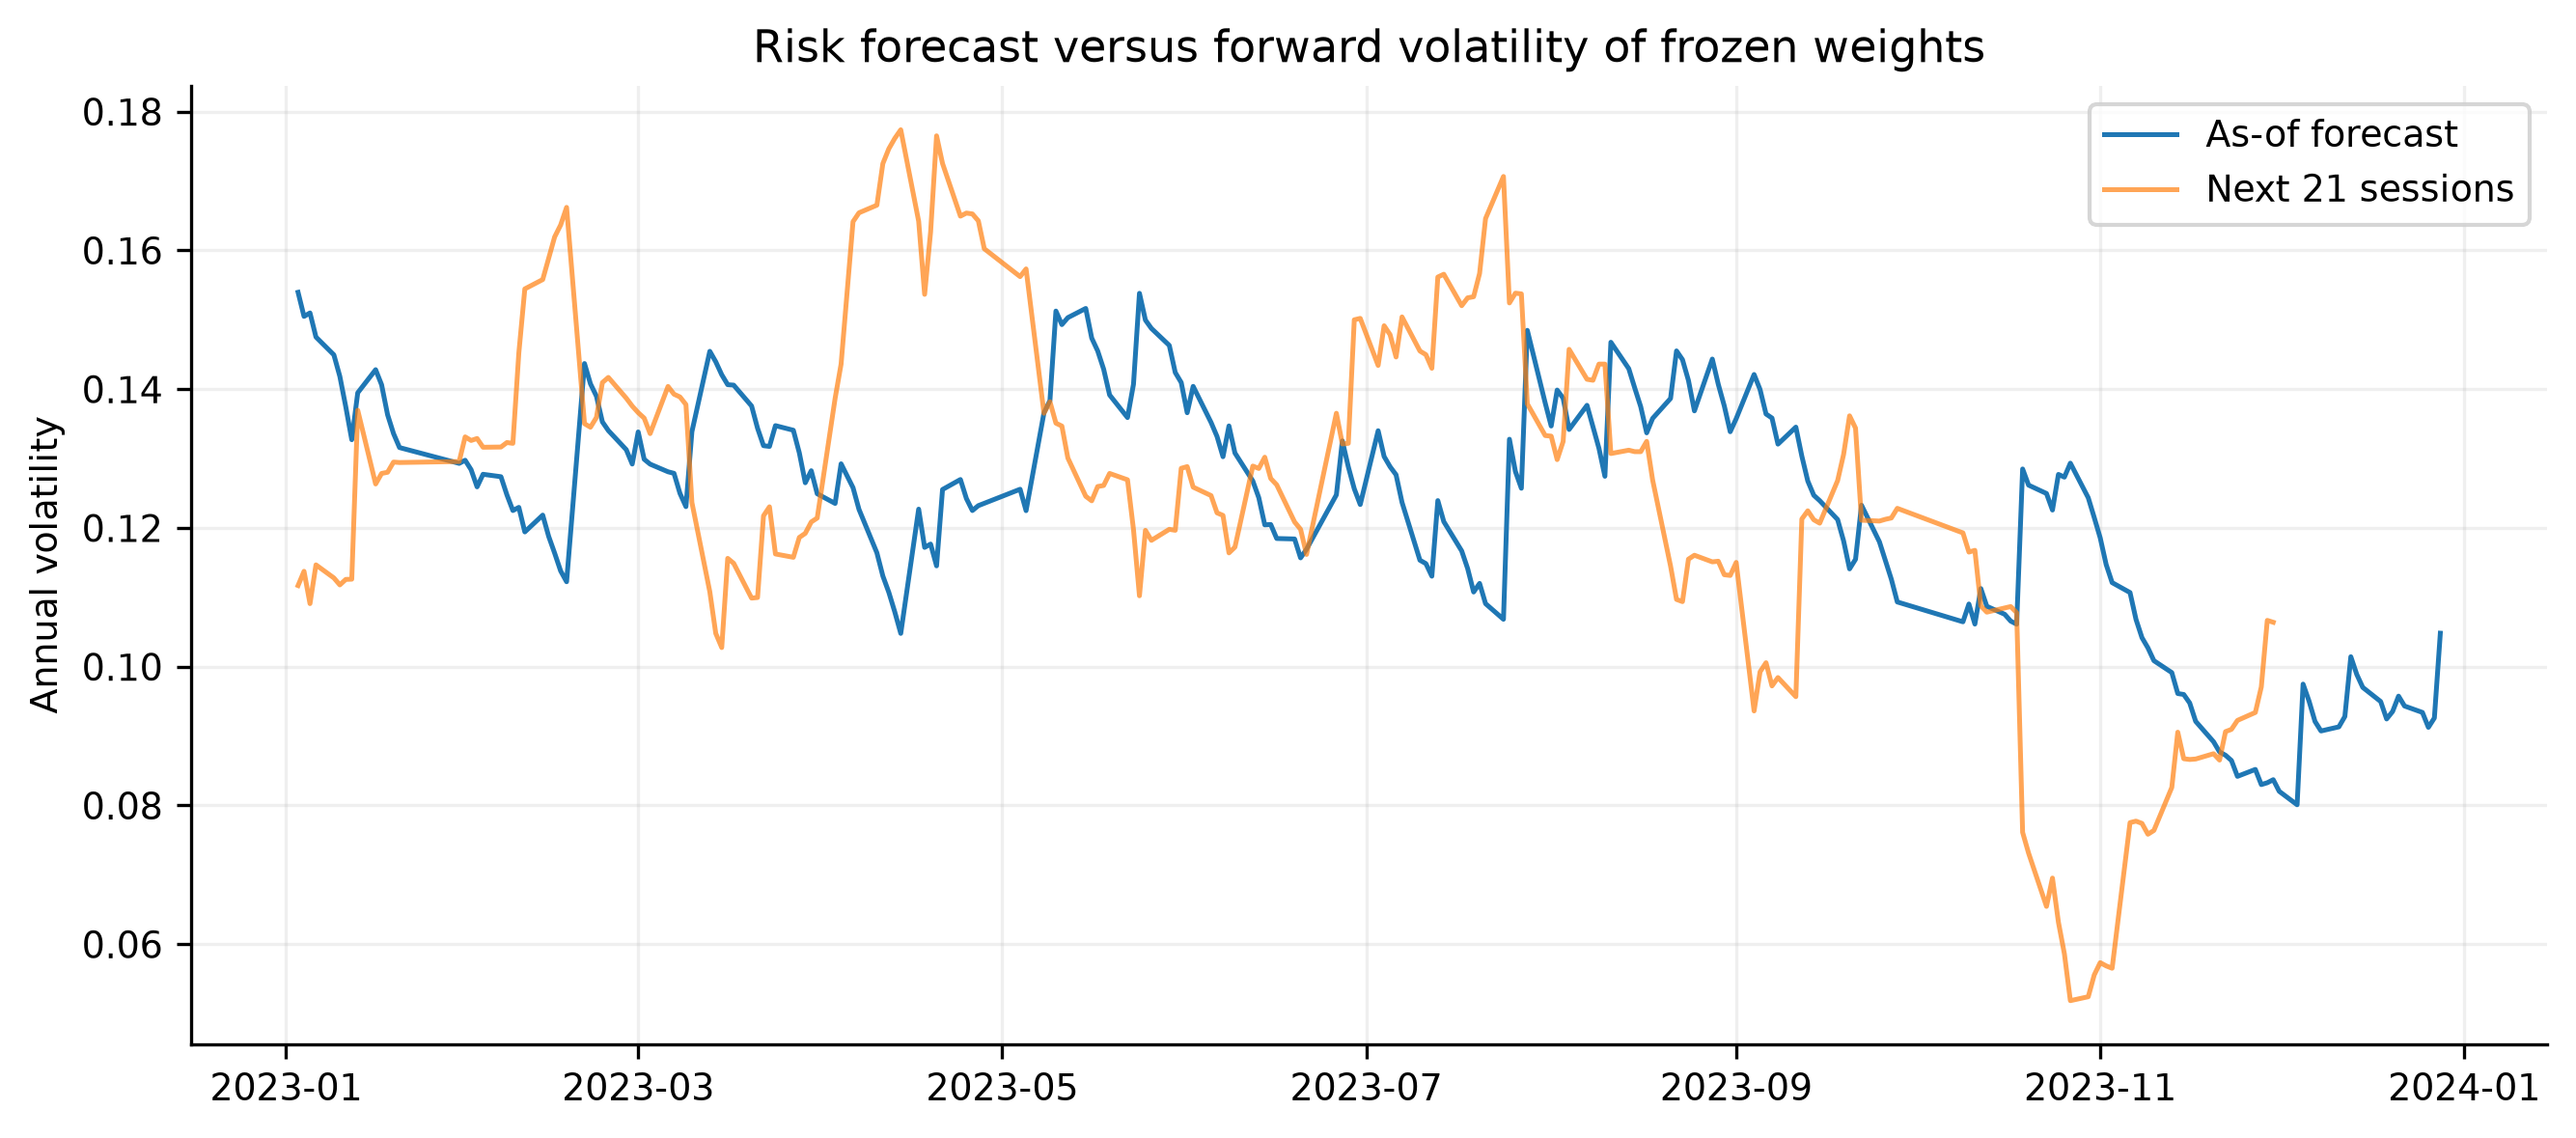

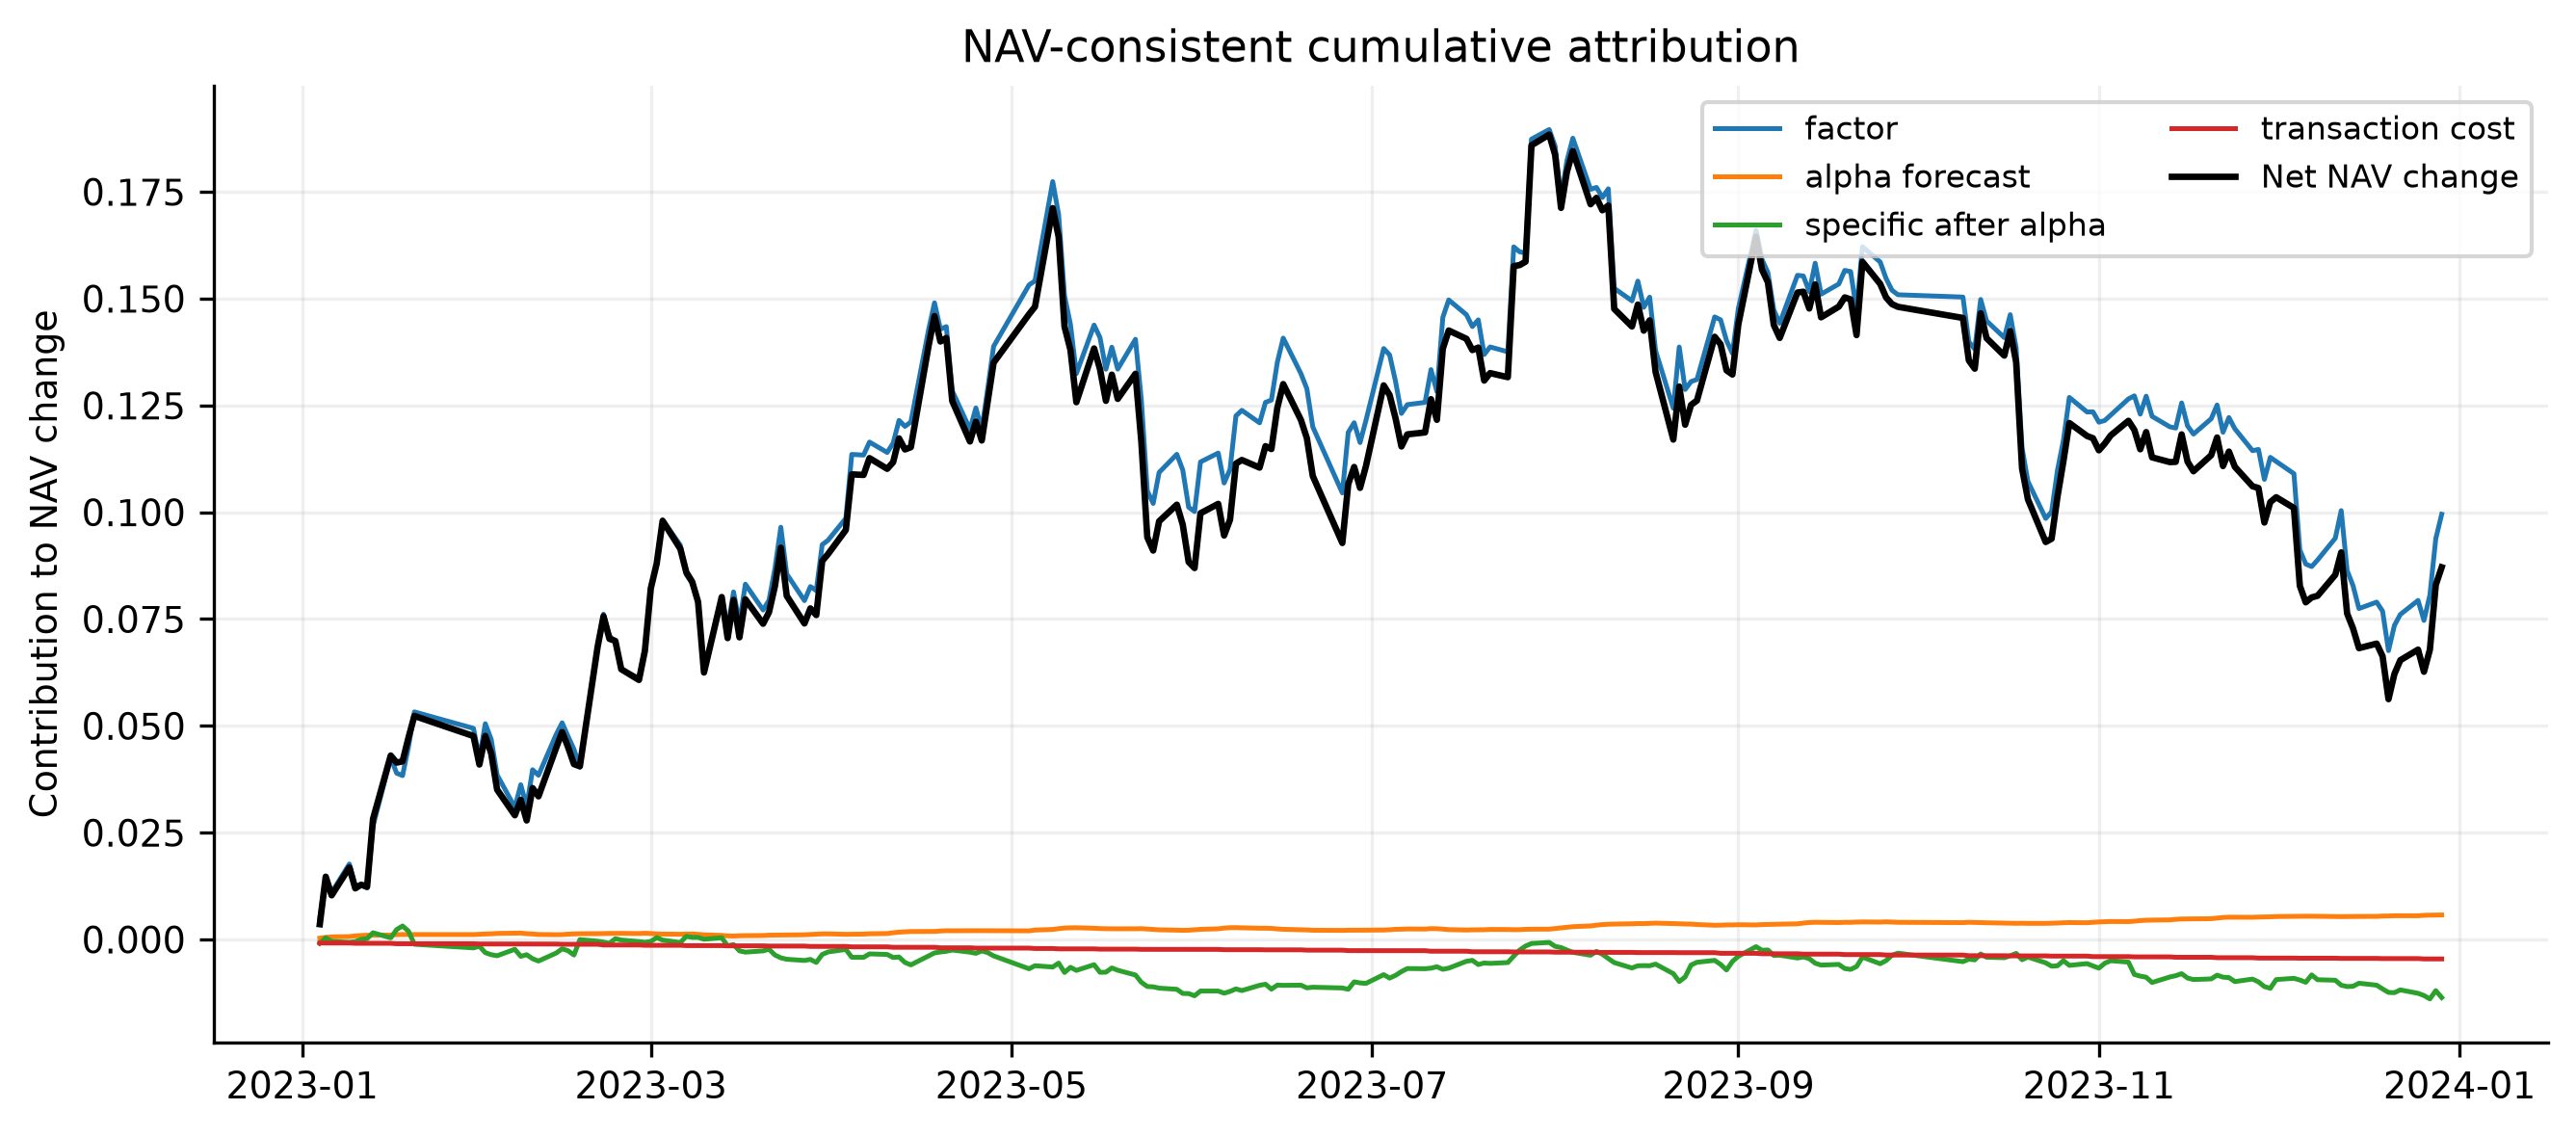

In [3]:
for name in ['cumulative_net_comparison', 'predicted_vs_realized_risk', 'factor_attribution']:
    display(Image(filename=str(output / f'figures/{name}.png'), width=850))

In [4]:
display(pd.read_csv(output / 'tables/robustness_summary.csv'))

,experiment,category,status,annualized_return,annualized_volatility,sharpe,max_drawdown,calmar,average_turnover,average_rebalance_turnover,...,average_net_exposure,maximum_position,effective_number_of_bets,normalized_effective_positions,gross_annualized_return,n_periods,mean_weight_instability_l1,maximum_weight_instability_l1,inaccurate_solver_fraction,mean_covariance_condition_number
0,risk_aversion_1.0,risk_aversion,completed,0.057195,0.138246,0.470984,-0.141304,0.404766,0.017167,0.082745,...,1.0,0.033870,41.501497,41.501497,0.062029,241.0,0.382305,0.443817,0.033195,189.608237
1,risk_aversion_5.0,risk_aversion,completed,0.091272,0.123771,0.767314,-0.111196,0.820816,0.016513,0.079593,...,1.0,0.033222,40.697755,40.697755,0.096052,241.0,0.000000,0.000000,0.033195,189.608237
2,risk_aversion_20.0,risk_aversion,completed,0.131010,0.116576,1.114254,-0.082322,1.591434,0.018808,0.090655,...,1.0,0.039173,39.340953,39.340953,0.136652,241.0,0.374649,0.451534,0.012448,189.608237
3,cost_penalty_0.0,cost_penalty,completed,0.064212,0.123124,0.566722,-0.117155,0.548090,0.065165,0.314094,...,1.0,0.033812,35.616307,35.616307,0.085423,241.0,0.625049,0.828472,0.000000,189.608237
4,cost_penalty_1.0,cost_penalty,completed,0.091272,0.123771,0.767314,-0.111196,0.820816,0.016513,0.079593,...,1.0,0.033222,40.697755,40.697755,0.096052,241.0,0.000000,0.000000,0.033195,189.608237
5,cost_penalty_5.0,cost_penalty,completed,0.064396,0.129733,0.545565,-0.116426,0.553107,0.004432,0.021361,...,1.0,0.033148,49.777327,49.777327,0.065344,241.0,0.494992,0.611685,0.066390,189.608237
6,max_weight_0.02,max_weight,completed,0.080850,0.127297,0.674073,-0.123346,0.655475,0.013834,0.066682,...,1.0,0.025924,52.424836,52.424836,0.084606,241.0,0.452968,0.535918,0.016598,189.608237
7,max_weight_0.05,max_weight,completed,0.081026,0.127815,0.673164,-0.116833,0.693520,0.017528,0.084486,...,1.0,0.055208,30.057075,30.057075,0.086223,241.0,0.432517,0.472878,0.020747,189.608237
8,max_weight_0.1,max_weight,completed,0.071461,0.133435,0.583620,-0.117217,0.609645,0.018245,0.087941,...,1.0,0.103801,21.090690,21.090690,0.076983,241.0,0.704243,0.792998,0.004149,189.608237
9,rebalance_frequency_daily,rebalance_frequency,completed,0.065896,0.121713,0.584881,-0.125390,0.525530,0.029445,0.029568,...,1.0,0.030157,40.008926,40.008926,0.074132,241.0,0.298580,0.537720,0.199170,189.608237


## Limits

Manual business groups, retrospective basket selection, incomplete publication/revision timestamps, idealized close fills and incomplete A-share event/settlement rules remain material limits. Read outputs/ashare/research_report.md and docs/ASHARE_VALIDATION.md for the full audit and reproduction commands.